<div style="background:linear-gradient(90deg,#4776e6,#8e54e9);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.85">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">The Perceptron (1958)</h1>
<p style="margin:0">The first artificial neuron that <b>learns its own weights from data</b>.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | 1958 |
| **Inventor** | Frank Rosenblatt (psychologist and computer scientist, Cornell Aeronautical Laboratory) |
| **Family** | Neural models → Supervised learning (binary classification) |
| **Learns from data?** | ✅ Yes, from its mistakes |
| **Inputs / Output** | Real numbers in, `0` or `1` out |
| **Builds on** | The McCulloch-Pitts neuron (1943) |
| **Difficulty** | ⭐⭐ Beginner |

### 🎯 What you will learn in this notebook
1. The story: the machine that made newspapers dream
2. How the Perceptron improves on the McCulloch-Pitts neuron
3. The formula and the learning rule
4. Learn the rule **by hand** with real numbers (the AND gate)
5. Build the Perceptron **from scratch** in Python
6. Train it on real flowers (Iris dataset) and watch the decision line move
7. Compare with scikit-learn's Perceptron
8. See exactly **when it fails** (XOR) and why that mattered

## 📖 Part 1: The story

The McCulloch-Pitts neuron (1943) was clever, but a human had to choose every number by hand. It **could not learn**.

In **1958**, psychologist **Frank Rosenblatt** asked: *what if the neuron adjusted its own numbers after seeing examples?*

He designed the **Perceptron**: a neuron with **weights** (how much each input matters) and a **learning rule** that nudges the weights whenever the neuron makes a mistake.

### 🏗️ A real machine
Rosenblatt did not only write equations. The **Mark I Perceptron** was a physical machine. It had a grid of 400 light sensors (a 20 × 20 "eye"), and the weights were stored in adjustable knobs (potentiometers) turned by electric motors. It learned to tell simple shapes apart.

### 📰 The hype
The US Navy funded the work, and newspapers wrote that machines like this might one day walk, talk, see and be conscious. That was far too optimistic, but the core idea was real and it is **still inside every neural network today**.

### 🧱 The wall
In the 1960s it was proved that if the classes can be separated by a straight line, the Perceptron **always** finds that line in a finite number of steps (the *perceptron convergence theorem*). But in **1969**, Marvin Minsky and Seymour Papert published *Perceptrons*, showing a single Perceptron cannot solve problems like **XOR**. This helped cool interest in neural networks for years.

### 🗺️ Where this fits
```
Least Squares (1805) → McCulloch-Pitts neuron (1943) → Perceptron (1958) → Backpropagation (1986) → Deep Learning (2012) → Transformers (2017)
```

## 🧠 Part 2: The idea in plain words

Imagine you decide whether to **go out for ice cream**. Some things matter more than others:

| Input | Weight | Meaning |
|---|---|---|
| Good weather | `+2` | helps a bit |
| Friends are going | `+3` | helps a lot |
| You have homework | `−4` | strongly stops you |
| **Bias** | `−1` | a general "I'm lazy" level |

You add up `weight × input` for every input, add the bias, and **go if the total is 0 or more**.

That is the Perceptron. The **only** new magic is that it **learns** those weights and the bias from examples.

### 🆚 McCulloch-Pitts vs Perceptron

| | McCulloch-Pitts (1943) | Perceptron (1958) |
|---|---|---|
| Inputs | Only `0` / `1` | Any real numbers |
| Weights | None (all inputs count equally) | One per input |
| Bias / threshold | Set by hand | Learned (as a bias) |
| Learning | ❌ No | ✅ Yes |

### ➗ The formulas

**1. Make a prediction**

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b \qquad\qquad \hat{y} = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{otherwise} \end{cases}$$

**2. Learn from a mistake** (the Perceptron learning rule)

$$\text{error} = y - \hat{y} \qquad\qquad w_i \leftarrow w_i + \eta \cdot \text{error} \cdot x_i \qquad\qquad b \leftarrow b + \eta \cdot \text{error}$$

where `y` is the true answer, `ŷ` is the prediction and `η` (eta) is the **learning rate**.

### 🔍 What the rule does

| Situation | error | Effect |
|---|---|---|
| Predicted `0`, truth is `1` | `+1` | weights move **toward** the input, so next time `z` is larger |
| Predicted `1`, truth is `0` | `−1` | weights move **away** from the input, so next time `z` is smaller |
| Correct | `0` | nothing changes |

That is the whole algorithm: **predict, check, nudge, repeat.**

## 🟣 Step 1: Import the libraries
> 💡 `numpy` for maths, `pandas` for tables, `matplotlib` for charts, and `scikit-learn` for the Iris dataset, splitting data and scoring.

In [1]:
# Import the libraries we need
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import Perceptron as SkPerceptron   # scikit-learn's version (for comparison later)

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, PURPLE, GREEN, ORANGE, RED, GREY, DARK = "#4776e6", "#8e54e9", "#27ae60", "#f39c12", "#e74c3c", "#7f8c8d", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: Picture the Perceptron
> 💡 Inputs are multiplied by their **weights**, added together with the **bias**, then a **step function** decides `0` or `1`.
> The picture is drawn with code, so no image files are needed.

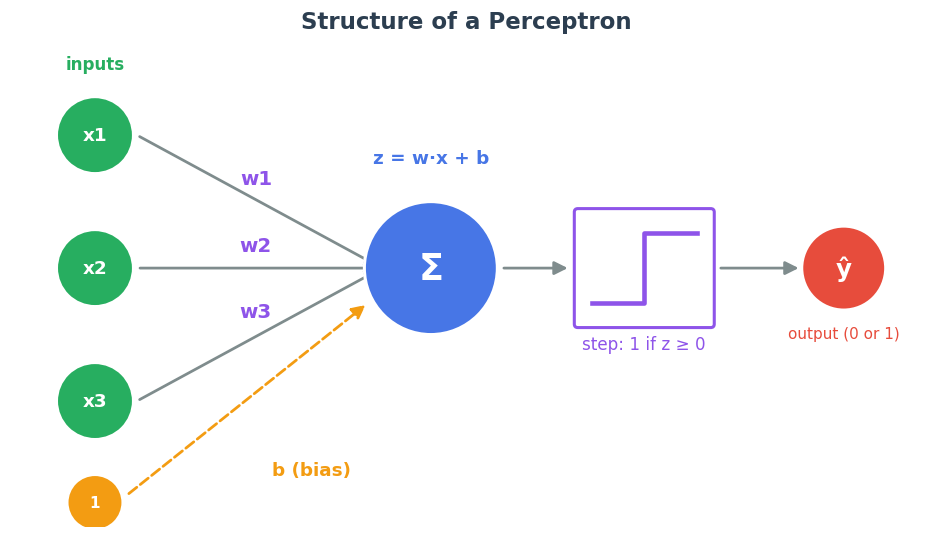

In [2]:
# Draw the structure of a Perceptron
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 13); ax.set_ylim(0, 7); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Structure of a Perceptron", fontsize=15, color=DARK, fontweight="bold")

# inputs and the arrows (weights) that go to the sum node
ys = [5.6, 3.7, 1.8]
for i, y in enumerate(ys, start=1):
    ax.add_patch(Circle((1.2, y), 0.55, color=GREEN, ec="white", lw=2))
    ax.text(1.2, y, f"x{i}", ha="center", va="center", color="white", fontweight="bold", fontsize=12)
    ax.add_patch(FancyArrowPatch((1.8, y), (5.3, 3.7), arrowstyle="-|>", mutation_scale=18, color=GREY, lw=1.8))
    ax.text(3.5, (y + 3.7) / 2 + 0.25, f"w{i}", color=PURPLE, fontsize=13, fontweight="bold", ha="center")

# bias input (always 1)
ax.add_patch(Circle((1.2, 0.35), 0.4, color=ORANGE, ec="white", lw=2))
ax.text(1.2, 0.35, "1", ha="center", va="center", color="white", fontweight="bold")
ax.add_patch(FancyArrowPatch((1.65, 0.45), (5.1, 3.2), arrowstyle="-|>", mutation_scale=18, color=ORANGE, lw=1.8, ls="--"))
ax.text(4.3, 0.75, "b (bias)", color=ORANGE, fontsize=12, fontweight="bold", ha="center")

# the weighted sum
ax.add_patch(Circle((6.0, 3.7), 0.95, color=BLUE, ec="white", lw=2))
ax.text(6.0, 3.7, "Σ", ha="center", va="center", color="white", fontsize=24, fontweight="bold")
ax.text(6.0, 5.2, "z = w·x + b", ha="center", color=BLUE, fontsize=12, fontweight="bold")

# the step function drawn inside a small box
ax.add_patch(FancyArrowPatch((7.0, 3.7), (8.0, 3.7), arrowstyle="-|>", mutation_scale=18, color=GREY, lw=1.8))
ax.add_patch(FancyBboxPatch((8.1, 2.9), 1.9, 1.6, boxstyle="round,pad=0.05", fc="white", ec=PURPLE, lw=2))
ax.plot([8.3, 9.05, 9.05, 9.8], [3.2, 3.2, 4.2, 4.2], color=PURPLE, lw=3)
ax.text(9.05, 2.55, "step: 1 if z ≥ 0", ha="center", color=PURPLE, fontsize=11)

# the output
ax.add_patch(FancyArrowPatch((10.1, 3.7), (11.3, 3.7), arrowstyle="-|>", mutation_scale=18, color=GREY, lw=1.8))
ax.add_patch(Circle((11.9, 3.7), 0.6, color=RED, ec="white", lw=2))
ax.text(11.9, 3.7, "ŷ", ha="center", va="center", color="white", fontsize=16, fontweight="bold")
ax.text(11.9, 2.7, "output (0 or 1)", ha="center", color=RED, fontsize=10)

ax.text(1.2, 6.55, "inputs", ha="center", color=GREEN, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## 🍦 Step 3: A decision with real numbers
> 💡 Before learning anything, let's **use** a Perceptron with weights we chose ourselves (the ice-cream example).
> `z = 2·weather + 3·friends − 4·homework − 1`, then go if `z ≥ 0`.

In [3]:
# A Perceptron with hand-picked weights: should we go for ice cream?
names = ["good weather", "friends going", "has homework"]
w = np.array([2, 3, -4])
b = -1

def decide(x):
    z = np.dot(w, x) + b          # weighted sum + bias
    return z, int(z >= 0)         # step function

rows = []
for x in itertools.product([0, 1], repeat=3):
    z, out = decide(x)
    rows.append({"weather": x[0], "friends": x[1], "homework": x[2], "z": z, "decision": "go 🍦" if out else "stay home"})
ice = pd.DataFrame(rows)

def colour(row):
    c = "background-color:#d5f5e3" if row["decision"].startswith("go") else "background-color:#fadbd8"
    return [c] * len(row)

ice.style.apply(colour, axis=1)

,weather,friends,homework,z,decision
0,0,0,0,-1,stay home
1,0,0,1,-5,stay home
2,0,1,0,2,go 🍦
3,0,1,1,-2,stay home
4,1,0,0,1,go 🍦
5,1,0,1,-3,stay home
6,1,1,0,4,go 🍦
7,1,1,1,0,go 🍦


## 📊 Step 4: Who pushed the decision?
> 💡 Take the case *good weather + friends going + has homework*. Each bar is one term of `z`. Green bars push towards **go**, red bars push towards **stay**.
> Here they cancel out exactly (`z = 0`), and since `0 ≥ 0` the Perceptron says **go**.

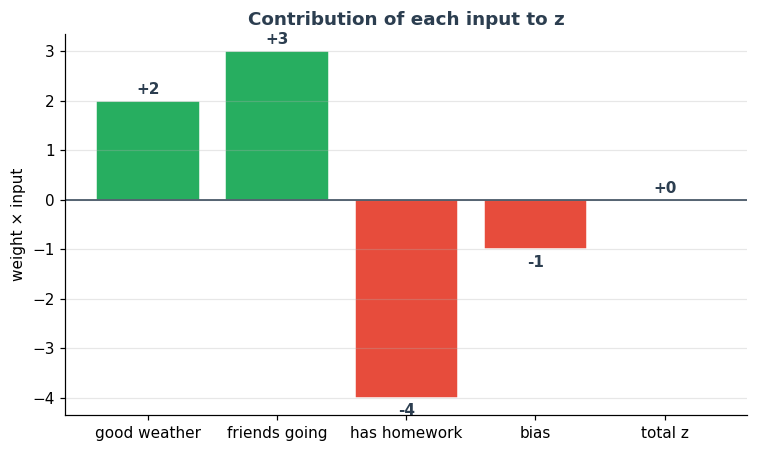

In [4]:
# Show each term of z as a bar for the case (weather=1, friends=1, homework=1)
x_case = np.array([1, 1, 1])
terms = list(w * x_case) + [b]
labels = names + ["bias"]
total = sum(terms)

plt.figure(figsize=(8, 4.5))
colors = [GREEN if t >= 0 else RED for t in terms] + [PURPLE]
plt.bar(labels + ["total z"], terms + [total], color=colors, edgecolor="white")
plt.axhline(0, color=DARK, lw=1)
plt.title("Contribution of each input to z", color=DARK, fontweight="bold")
plt.ylabel("weight × input")
for i, v in enumerate(terms + [total]):
    plt.text(i, v + (0.15 if v >= 0 else -0.35), f"{v:+.0f}", ha="center", fontweight="bold", color=DARK)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🤖 Step 5: Build the Perceptron from scratch
> 💡 A small Python class with two jobs:
> - `fit(X, y)`: **learn** by looping over the data again and again (each full loop is an **epoch**) and applying the learning rule on every mistake
> - `predict(X)`: use the learned weights to answer
>
> We also record the number of mistakes in each epoch and the weights after each epoch, so we can plot them later. Training stops early when an epoch has **zero mistakes**.

In [5]:
# The Perceptron class
class Perceptron:
    '''A from-scratch Perceptron (Rosenblatt, 1958).'''

    def __init__(self, lr=0.1, epochs=50):
        self.lr = lr                 # learning rate (eta)
        self.epochs = epochs         # maximum number of passes over the data

    def predict(self, X):
        z = np.asarray(X, dtype=float) @ self.w_ + self.b_
        return (z >= 0).astype(int)  # step function

    def fit(self, X, y, log=False):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.w_ = np.zeros(X.shape[1])   # start with all weights = 0
        self.b_ = 0.0                    # and bias = 0
        self.errors_ = []                # mistakes per epoch
        self.history_ = []               # (weights, bias) at the end of each epoch
        self.updates_ = []               # (weights, bias) after every single mistake
        self.log_ = []                   # step-by-step log (only if log=True)

        for epoch in range(1, self.epochs + 1):
            mistakes = 0
            for xi, target in zip(X, y):
                z = xi @ self.w_ + self.b_
                pred = int(z >= 0)
                error = target - pred
                if error != 0:                          # learning rule: only on mistakes
                    self.w_ = self.w_ + self.lr * error * xi
                    self.b_ = self.b_ + self.lr * error
                    mistakes += 1
                    self.updates_.append((self.w_.copy(), self.b_))
                if log:
                    self.log_.append({"epoch": epoch, **{f"x{j+1}": xi[j] for j in range(len(xi))},
                                      "target": target, "z": round(z, 2), "prediction": pred, "error": error,
                                      **{f"w{j+1}": round(self.w_[j], 2) for j in range(len(xi))},
                                      "bias": round(self.b_, 2)})
            self.errors_.append(mistakes)
            self.history_.append((self.w_.copy(), self.b_))
            if mistakes == 0:                           # perfect epoch → learned!
                break
        return self

print("✅ Perceptron class created!")

✅ Perceptron class created!


## ✍️ Step 6: Watch it learn the AND gate, step by step
> 💡 We use learning rate `η = 1` so all the numbers stay whole and easy to follow.
> Every row is **one example**. Rows with an error (red) are the moments the weights change.
> Read the last columns to see the weights and bias after that row.

In [6]:
# Train on the AND gate and show every single step
X_and = np.array(list(itertools.product([0, 1], repeat=2)))   # (0,0) (0,1) (1,0) (1,1)
y_and = np.array([0, 0, 0, 1])

p_and = Perceptron(lr=1, epochs=20).fit(X_and, y_and, log=True)
steps = pd.DataFrame(p_and.log_)

def mark_mistakes(row):
    c = "background-color:#fadbd8" if row["error"] != 0 else ""
    return [c] * len(row)

print(f"✅ Learned AND after {len(p_and.errors_)} epochs. Final weights = {p_and.w_}, bias = {p_and.b_}")
steps.style.apply(mark_mistakes, axis=1)

✅ Learned AND after 6 epochs. Final weights = [2. 1.], bias = -3.0


,epoch,x1,x2,target,z,prediction,error,w1,w2,bias
0,1,0.000000,0.000000,0,0.000000,1,-1,0.000000,0.000000,-1.000000
1,1,0.000000,1.000000,0,-1.000000,0,0,0.000000,0.000000,-1.000000
2,1,1.000000,0.000000,0,-1.000000,0,0,0.000000,0.000000,-1.000000
3,1,1.000000,1.000000,1,-1.000000,0,1,1.000000,1.000000,0.000000
4,2,0.000000,0.000000,0,0.000000,1,-1,1.000000,1.000000,-1.000000
5,2,0.000000,1.000000,0,0.000000,1,-1,1.000000,0.000000,-2.000000
6,2,1.000000,0.000000,0,-1.000000,0,0,1.000000,0.000000,-2.000000
7,2,1.000000,1.000000,1,-1.000000,0,1,2.000000,1.000000,-1.000000
8,3,0.000000,0.000000,0,-1.000000,0,0,2.000000,1.000000,-1.000000
9,3,0.000000,1.000000,0,0.000000,1,-1,2.000000,0.000000,-2.000000


## ✅ Step 7: Check what it learned
> 💡 Test the final weights on all four inputs, and show the **line** the Perceptron drew.
> It fires only when `w1·x1 + w2·x2 + b ≥ 0`, so the boundary is the line `w1·x1 + w2·x2 + b = 0`.

Predictions: [0 0 0 1] | Truth: [0 0 0 1]


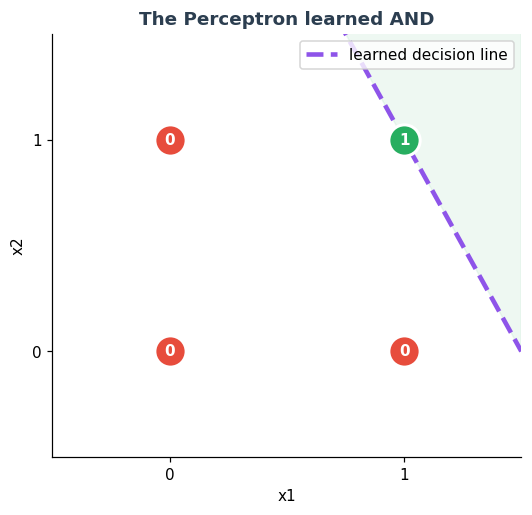

In [7]:
# Verify the AND gate and plot its decision line
print("Predictions:", p_and.predict(X_and), "| Truth:", y_and)
assert (p_and.predict(X_and) == y_and).all()

plt.figure(figsize=(5.5, 5))
for (a, c), t in zip(X_and, y_and):
    plt.scatter(a, c, s=420, color=GREEN if t else RED, edgecolor="white", linewidth=2, zorder=3)
    plt.text(a, c, str(t), ha="center", va="center", color="white", fontweight="bold", zorder=4)

w1, w2 = p_and.w_
xs = np.linspace(-0.5, 1.5, 50)
plt.plot(xs, -(w1 * xs + p_and.b_) / w2, color=PURPLE, lw=3, ls="--", label="learned decision line")
plt.fill_between(xs, -(w1 * xs + p_and.b_) / w2, 2, color=GREEN, alpha=0.08)
plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)
plt.xticks([0, 1]); plt.yticks([0, 1])
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("The Perceptron learned AND", color=DARK, fontweight="bold")
plt.legend(loc="upper right")
plt.show()

## 🌸 Step 8: Real data: tell two flowers apart
> 💡 The **Iris dataset** is built into scikit-learn. We take two species, **setosa** and **versicolor**, and use two measurements: **petal length** and **petal width**.
> Can a straight line separate them? Let's look.

Rows: 100 | Species: ['setosa', 'versicolor']
            petal length (cm)  petal width (cm)
target                                         
setosa                   1.46              0.25
versicolor               4.26              1.33


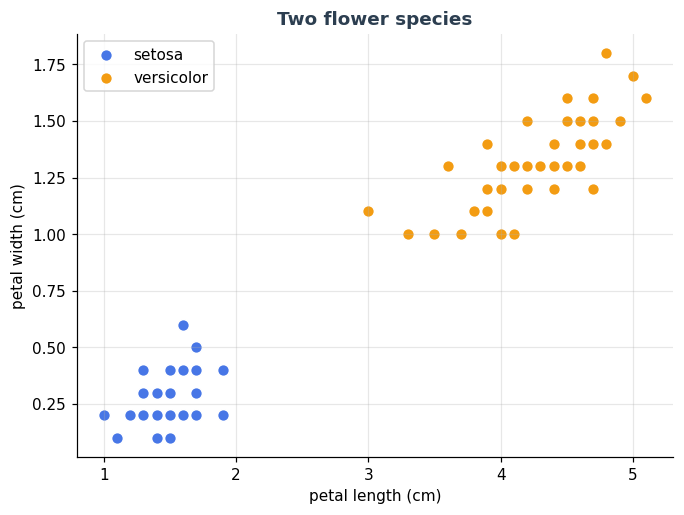

In [8]:
# Load the Iris data and keep two species and two features
iris = load_iris(as_frame=True)
df = iris.frame
df = df[df["target"].isin([0, 1])]                         # 0 = setosa, 1 = versicolor
features = ["petal length (cm)", "petal width (cm)"]
X = df[features].values
y = df["target"].values

print("Rows:", len(df), "| Species:", [str(n) for n in iris.target_names[:2]])
print(df.groupby("target")[features].mean().round(2).rename(index={0: "setosa", 1: "versicolor"}))

plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color=BLUE, label="setosa", edgecolor="white", s=60)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color=ORANGE, label="versicolor", edgecolor="white", s=60)
plt.xlabel(features[0]); plt.ylabel(features[1])
plt.title("Two flower species", color=DARK, fontweight="bold")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## ✂️ Step 9: Split and train
> 💡 Like before: **70%** to learn from, **30%** to test on flowers the Perceptron has never seen. `stratify=y` keeps the species balanced in both parts.

In [9]:
# Split the data and train our Perceptron
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

model = Perceptron(lr=0.1, epochs=100).fit(X_train, y_train)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print("Epochs used:", len(model.errors_), "(the two species are far apart, so learning is quick)")
print("Mistakes per epoch:", model.errors_)
print("Learned weights:", np.round(model.w_, 3), "| bias:", round(model.b_, 3))

Training rows: 70 | Testing rows: 30
Epochs used: 2 (the two species are far apart, so learning is quick)
Mistakes per epoch: [7, 0]
Learned weights: [0.06 0.16] | bias: -0.3


## 📈 Step 10: The learning curve
> 💡 Each bar is how many mistakes the Perceptron made in that epoch. It should go **down to zero**. When it reaches zero, learning is finished.

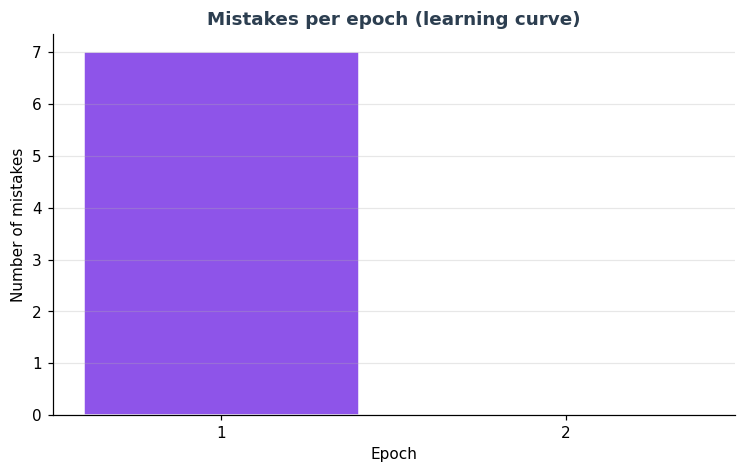

In [10]:
# Plot mistakes per epoch
plt.figure(figsize=(8, 4.5))
epochs_axis = np.arange(1, len(model.errors_) + 1)
plt.bar(epochs_axis, model.errors_, color=PURPLE, edgecolor="white")
plt.title("Mistakes per epoch (learning curve)", color=DARK, fontweight="bold")
plt.xlabel("Epoch"); plt.ylabel("Number of mistakes")
plt.xticks(epochs_axis if len(epochs_axis) <= 20 else None)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 🎞️ Step 11: Watch the line move
> 💡 Every time the Perceptron makes a mistake, its weights change, so its decision line changes too. Faint lines are early guesses; the **bold red line** is the final one.
> You can see it rotating and shifting until it sits between the two groups.

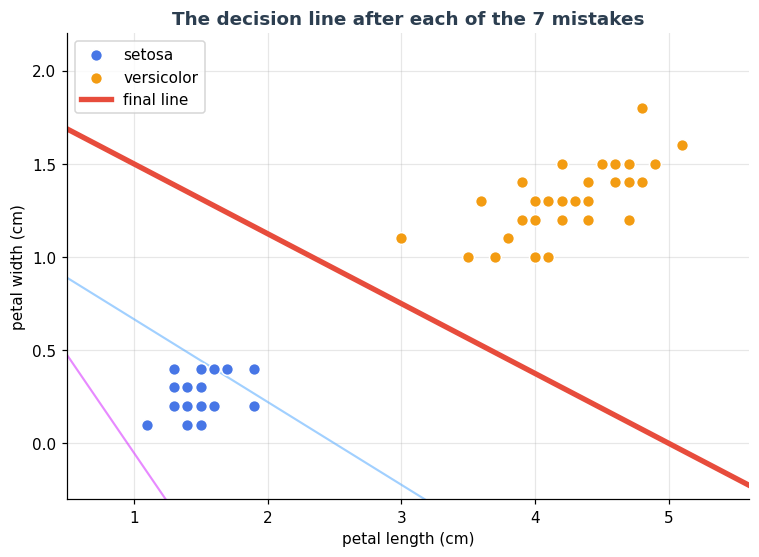

In [11]:
# Plot the decision line after every mistake (every weight update)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], color=BLUE, label="setosa", edgecolor="white", s=60, zorder=3)
ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], color=ORANGE, label="versicolor", edgecolor="white", s=60, zorder=3)

xs = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
n = len(model.updates_)
cmap = plt.cm.cool
for k, (wk, bk) in enumerate(model.updates_):
    if abs(wk[1]) < 1e-12:
        continue                                          # vertical line, skip for simplicity
    last = (k == n - 1)
    ax.plot(xs, -(wk[0] * xs + bk) / wk[1], color=RED if last else cmap(k / max(n - 1, 1)),
            lw=3.5 if last else 1.4, alpha=1 if last else 0.55, label="final line" if last else None)

ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
ax.set_ylim(X[:, 1].min() - 0.4, X[:, 1].max() + 0.4)
ax.set_xlabel(features[0]); ax.set_ylabel(features[1])
ax.set_title(f"The decision line after each of the {n} mistakes", color=DARK, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 📝 Step 12: Grade it on unseen flowers
> 💡 **Accuracy** = fraction of correct answers. This time accuracy makes sense, because we are classifying, not predicting a number.
> The **confusion matrix** shows exactly which mistakes happen (rows = truth, columns = prediction).

Train accuracy: 100.00%
Test accuracy:  100.00%


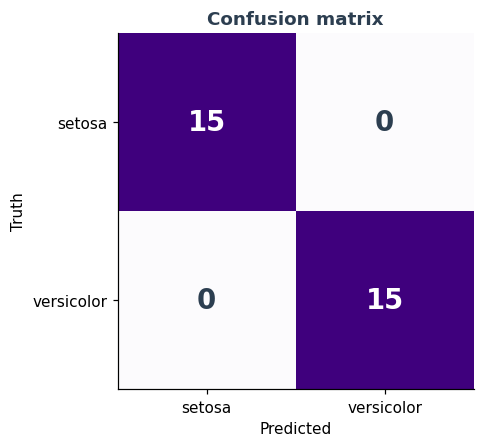

In [12]:
# Accuracy and confusion matrix on the test set
y_pred = model.predict(X_test)
print(f"Train accuracy: {accuracy_score(y_train, model.predict(X_train)):.2%}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred):.2%}")

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap="Purples")
ax.set_xticks([0, 1]); ax.set_xticklabels(["setosa", "versicolor"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["setosa", "versicolor"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Truth")
ax.set_title("Confusion matrix", color=DARK, fontweight="bold")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=18, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else DARK)
plt.show()

## 🔮 Step 13: Predict new flowers
> 💡 Give the model measurements it has never seen: `[petal length, petal width]`.

In [13]:
# Predict two brand-new flowers
new_flowers = np.array([[1.4, 0.2],     # small petals
                        [4.5, 1.4]])    # bigger petals
species = ["setosa", "versicolor"]
for flower, pred in zip(new_flowers, model.predict(new_flowers)):
    print(f"Petal length {flower[0]}, width {flower[1]}  →  {species[pred]}")

Petal length 1.4, width 0.2  →  setosa
Petal length 4.5, width 1.4  →  versicolor


## 🧪 Step 14: Compare with scikit-learn's Perceptron
> 💡 In real projects you use the library version. It is the same idea with extra options.
> If our from-scratch code is right, the accuracy should match.

In [14]:
# Train scikit-learn's Perceptron on the same data and compare
sk_model = SkPerceptron(max_iter=1000, random_state=42)
sk_model.fit(X_train, y_train)

print(f"Our Perceptron          → test accuracy: {accuracy_score(y_test, model.predict(X_test)):.2%}")
print(f"scikit-learn Perceptron → test accuracy: {accuracy_score(y_test, sk_model.predict(X_test)):.2%}")
print("\nsklearn weights:", np.round(sk_model.coef_[0], 3), "| bias:", np.round(sk_model.intercept_[0], 3))

Our Perceptron          → test accuracy: 100.00%
scikit-learn Perceptron → test accuracy: 100.00%

sklearn weights: [1.7 2.7] | bias: -6.0


## 🚪 Step 15: Which logic gates can it learn?
> 💡 The McCulloch-Pitts neuron needed us to choose numbers. Now the Perceptron finds them itself.
> Let's train one Perceptron per gate and see who succeeds. `Converged?` means it reached an epoch with zero mistakes.

In [15]:
# Train one Perceptron per logic gate (with 50 epochs max) and compare
gates = {"AND":  [0, 0, 0, 1],
         "OR":   [0, 1, 1, 1],
         "NAND": [1, 1, 1, 0],
         "NOR":  [1, 0, 0, 0],
         "XOR":  [0, 1, 1, 0]}

rows = []
trained = {}
for name, truth in gates.items():
    p = Perceptron(lr=1, epochs=50).fit(X_and, truth)
    trained[name] = p
    rows.append({"gate": name,
                 "converged?": "✅ yes" if p.errors_[-1] == 0 else "❌ never",
                 "epochs used": len(p.errors_),
                 "accuracy": f"{accuracy_score(truth, p.predict(X_and)):.0%}"})
pd.DataFrame(rows)

,gate,converged?,epochs used,accuracy
0,AND,✅ yes,6,100%
1,OR,✅ yes,4,100%
2,NAND,✅ yes,6,100%
3,NOR,✅ yes,4,100%
4,XOR,❌ never,50,50%


## ❌ Step 16: The wall: XOR
> 💡 XOR cannot be separated by **any** straight line (we saw this in the previous story). So the Perceptron keeps changing its mind forever.
> Left: the mistakes per epoch never reach zero. Right: why no line works.

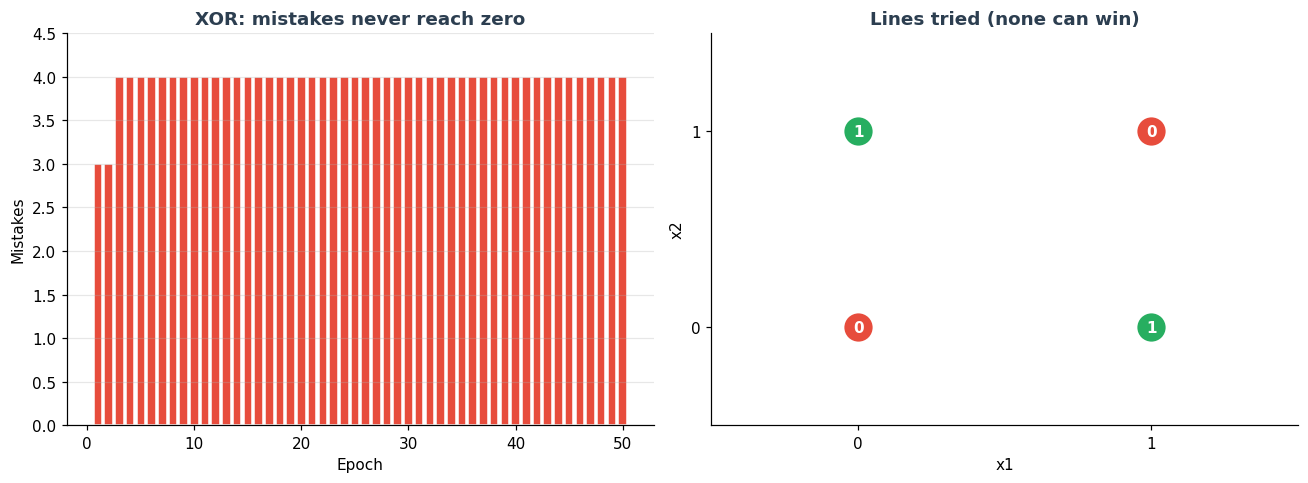

In [16]:
# Show that XOR never converges
p_xor = trained["XOR"]
xor_truth = gates["XOR"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(range(1, len(p_xor.errors_) + 1), p_xor.errors_, color=RED, edgecolor="white")
ax1.set_title("XOR: mistakes never reach zero", color=DARK, fontweight="bold")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Mistakes")
ax1.set_ylim(0, 4.5); ax1.grid(axis="y", alpha=0.3)

for (a, c), t in zip(X_and, xor_truth):
    ax2.scatter(a, c, s=420, color=GREEN if t else RED, edgecolor="white", linewidth=2, zorder=3)
    ax2.text(a, c, str(t), ha="center", va="center", color="white", fontweight="bold", zorder=4)
xs = np.linspace(-0.5, 1.5, 50)
for (wk, bk) in p_xor.history_[:12]:
    if abs(wk[1]) > 1e-12:
        ax2.plot(xs, -(wk[0] * xs + bk) / wk[1], color=PURPLE, alpha=0.35, lw=1.5)
ax2.set_xlim(-0.5, 1.5); ax2.set_ylim(-0.5, 1.5)
ax2.set_xticks([0, 1]); ax2.set_yticks([0, 1])
ax2.set_xlabel("x1"); ax2.set_ylabel("x2")
ax2.set_title("Lines tried (none can win)", color=DARK, fontweight="bold")
plt.tight_layout()
plt.show()

## 🎚️ Step 17: Does the learning rate matter?
> 💡 Surprise: when we start with weights = 0, the learning rate **does not change what the Perceptron learns**. It only scales the weights up or down by the same factor.
> Let's check with three very different learning rates. (We use powers of two, so the computer's arithmetic stays exact.)

In [17]:
# Train the AND gate with very different learning rates
rows = []
for lr in [0.25, 1, 8]:
    p = Perceptron(lr=lr, epochs=50).fit(X_and, y_and)
    rows.append({"learning rate": lr, "epochs used": len(p.errors_),
                 "w1": p.w_[0], "w2": p.w_[1], "bias": p.b_,
                 "w1 / lr": p.w_[0] / lr, "w2 / lr": p.w_[1] / lr, "bias / lr": p.b_ / lr})
pd.DataFrame(rows)

,learning rate,epochs used,w1,w2,bias,w1 / lr,w2 / lr,bias / lr
0,0.25,6,0.5,0.25,-0.75,2.0,1.0,-3.0
1,1.00,6,2.0,1.00,-3.00,2.0,1.0,-3.0
2,8.00,6,16.0,8.00,-24.00,2.0,1.0,-3.0


## ⚠️ Limitations of the Perceptron

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **Only straight lines** | Works only when the classes are *linearly separable* (no XOR) | Multi-layer networks + Backpropagation (1986) |
| ❌ **Never stops if not separable** | It keeps updating forever on overlapping data | Adaline (1960), Logistic Regression, SVM |
| ❌ **Hard yes/no answer** | No probability or confidence | Logistic Regression, Softmax |
| ❌ **Depends on data order** | Different order → a different (valid) line | Gradient-based training |
| ❌ **Binary only** | Two classes at a time | Multi-class extensions (one-vs-rest, softmax) |

### 🧬 What it gave us
- The idea of **learning weights from examples** by correcting mistakes
- The structure `weighted sum + bias → activation` that **every neuron in deep learning still uses**
- A guarantee (convergence theorem) that learning works when a solution exists

## 📝 Summary
1. ✅ The Perceptron (1958) is a neuron with **weights, a bias and a learning rule**.
2. ✅ It predicts with `z = w·x + b` and a step function.
3. ✅ It learns by nudging weights **only when it makes a mistake**.
4. ✅ It finds a separating **straight line** whenever one exists (we saw AND, OR, NAND, NOR and the Iris flowers).
5. ✅ It **cannot** solve XOR. Fixing that needed several neurons in layers, which is where the story goes next.

## 🧪 Practice time
**Exercise 1.** Train a Perceptron on the **NAND** gate and print its weights and bias. Then check that it predicts all four rows correctly.

**Exercise 2.** In Step 8, switch to **versicolor vs virginica** (target values `1` and `2`). Does the Perceptron reach zero mistakes? Why or why not?

**Exercise 3.** Design your own Perceptron **by hand** (choose the weights yourself) for: *"Take an umbrella if it's cloudy (+2) or the forecast says rain (+3), but not if it is windy (−3)."* Find a bias that makes it work.

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1
p = Perceptron(lr=1, epochs=50).fit(X_and, [1, 1, 1, 0])
print(p.w_, p.b_, p.predict(X_and))            # predictions should be [1 1 1 0]

# Exercise 2
d2 = iris.frame[iris.frame["target"].isin([1, 2])]
X2, y2 = d2[features].values, (d2["target"].values == 2).astype(int)
m2 = Perceptron(lr=0.1, epochs=200).fit(X2, y2)
print(m2.errors_[-5:])
# The last epochs usually still contain a few mistakes: these two species overlap a little,
# so no single straight line separates them perfectly.

# Exercise 3: inputs = cloudy, rain forecast, windy
w3, b3 = np.array([2, 3, -3]), -1
for x in itertools.product([0, 1], repeat=3):
    print(x, int(np.dot(w3, x) + b3 >= 0))
# bias -1 means: take the umbrella if there is at least some positive reason
# and wind does not cancel it out.
```
</details>

## ⏭️ What's next in AI-Genesis
The story continues: from **one neuron** to **many neurons in layers**, and how they finally learn to solve problems like XOR. 🚀